Name: Sana Raza

Labpartner(s)

In [1]:
#import statements go here
from datetime import datetime, timedelta
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

# Class 12.1

# Warmups 12.1

Note: finish this for lab if you don't finish in class.

Log into the Supermike III LSU HPC using ssh (in the terminal). See the help docs we went over last time. 

**W.1.** Investigate each of the following basic unix/linux commands:
- ls
- pwd
- cd
- scp
- scp -r

What do each of these do? If you forgot, you can type "man ls", etc. to see the documentation.

**W.2** Look up the LSU HPC documentation for /work and /home, what is the difference? What are the quotas for each? How long will files last? Are they backed up?

# Lecture 12.1

### Agenda:


Some useful things to do with a timeseries
- datetime objects
- basic line fitting
- moving averages
- detrending

In [2]:
from datetime import datetime, timedelta
import pandas as pd

#### Defining a specfic date

In [3]:
date1 = datetime(1996,1,1) 

In [4]:
# this is a datetime object
date1

datetime.datetime(1996, 1, 1, 0, 0)

In [5]:
# print out the date
print(date1)

1996-01-01 00:00:00


In [6]:
# you can also format the date as a string however you like (useful for plots)
date1.strftime("%m/%d/%Y")

'01/01/1996'

In [7]:
# defining a date with hours, minutes and seconds
date2 = datetime(1996,1,1, 13, 34, 6) # note using 24 clock (miltary time) here

In [8]:
print(date2)

1996-01-01 13:34:06


In [9]:
#what is going to happen here?
date2.strftime("%m-%d-%Y")

'01-01-1996'

In [10]:
date1.today() #somehow it knows what timezone I am (probably from my computer)

datetime.datetime(2026, 11, 14, 21, 4, 37, 320003)

#### If we want to increment the date we can use timedelta

In [11]:
date1 = date1 + timedelta(days=1)
print(date1)

1996-01-02 00:00:00


In [12]:
date1 = date1 + timedelta(minutes = 2, seconds=1)
print(date1)

1996-01-02 00:02:01


In [13]:
# you can also do things like add fractional days
date1 = date1 + timedelta(days=1.5)
print(date1)

1996-01-03 12:02:01


We can find the time difference between two dates

In [14]:
timediff = date2-date1
timediff

datetime.timedelta(days=-2, seconds=5525)

#### We can also define timeseries using pandas 

In [15]:
pd.date_range?

Signature:
pd.date_range(
    start=None,
    end=None,
    periods=None,
    freq=None,
    tz=None,
    normalize: 'bool' = False,
    name: 'Hashable | None' = None,
    inclusive: 'IntervalClosedType' = 'both',
    *,
    unit: 'TimeUnit | None' = None,
    **kwargs,
) -> 'DatetimeIndex'
Docstring:
Return a fixed frequency DatetimeIndex.

Returns the range of equally spaced time points (where the difference between any
two adjacent points is specified by the given frequency) such that they fall in the
range `[start, end]` , where the first one and the last one are, resp., the first
and last time points in that range that fall on the boundary of ``freq`` (if given
as a frequency string) or that are valid for ``freq`` (if given as a
:class:`pandas.tseries.offsets.DateOffset`). If ``freq`` is positive, the points
satisfy `start <[=] x <[=] end`, and if ``freq`` is negative, the points satisfy
`end <[=] x <[=] start`. (If exactly one of ``start``, ``end``, or ``freq`` is *not*
specifie

In [16]:
# note the default is daily
my_daterange = pd.date_range(start='1/1/2018', end='1/08/2018')

In [17]:
my_daterange

DatetimeIndex(['2018-01-01', '2018-01-02', '2018-01-03', '2018-01-04',
               '2018-01-05', '2018-01-06', '2018-01-07', '2018-01-08'],
              dtype='datetime64[us]', freq='D')

In [18]:
# this can be indexed like any array
my_daterange[-1]
# note the result is a timestamp, which is similar to a datetime object, but not exactly

Timestamp('2018-01-08 00:00:00')

In [19]:
print(my_daterange[1])

2018-01-02 00:00:00


In [20]:
# you can convert a datetime to a timestamp
pd.Timestamp(datetime(2012, 5, 1))

Timestamp('2012-05-01 00:00:00')

In [21]:
# we can also specfiy the frequency
my_daterange2 = pd.date_range(start='1/1/2018',end = '12/1/2021', freq='ME')
my_daterange2

DatetimeIndex(['2018-01-31', '2018-02-28', '2018-03-31', '2018-04-30',
               '2018-05-31', '2018-06-30', '2018-07-31', '2018-08-31',
               '2018-09-30', '2018-10-31', '2018-11-30', '2018-12-31',
               '2019-01-31', '2019-02-28', '2019-03-31', '2019-04-30',
               '2019-05-31', '2019-06-30', '2019-07-31', '2019-08-31',
               '2019-09-30', '2019-10-31', '2019-11-30', '2019-12-31',
               '2020-01-31', '2020-02-29', '2020-03-31', '2020-04-30',
               '2020-05-31', '2020-06-30', '2020-07-31', '2020-08-31',
               '2020-09-30', '2020-10-31', '2020-11-30', '2020-12-31',
               '2021-01-31', '2021-02-28', '2021-03-31', '2021-04-30',
               '2021-05-31', '2021-06-30', '2021-07-31', '2021-08-31',
               '2021-09-30', '2021-10-31', '2021-11-30'],
              dtype='datetime64[us]', freq='ME')

See the documentation for lots more functionality

### Working with timeseries data: global sea surface temperature (SST)

We are going to be using some data from the epa website here: https://www.epa.gov/climate-indicators/climate-change-indicators-sea-surface-temperature

This is globally averaged Extended Reconstructed Sea Surface Temperature (ERSST)v.4 from NOAA, which combines satilite, ship and other in situ (in place, i.e. in the water) data. If you follow the links on the above you can get the gridded (i.e. map) product in netcdf format for the latest product (v.5). We are just going to play around with the globally averaged data

In [22]:
# sst= pd.read_csv('https://www.epa.gov/system/files/other-files/2024-06/sea-surface-temp_fig-1.csv')

# this was giving me an error hence  I commented it out

That didn't work. I did some googling to figure out why and added an encoding specification: 

In [23]:
sst= pd.read_csv('https://www.epa.gov/system/files/other-files/2024-06/sea-surface-temp_fig-1.csv',
                encoding = 'latin1')

In [24]:
sst

,"Figure 1. Average Global Sea Surface Temperature, 1880-2023",Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Source: EPA's Climate Change Indicators in the...,NaN,NaN,NaN
1,"Data source: NOAA, 2024",NaN,NaN,NaN
2,Web update: June 2024,NaN,NaN,NaN
3,Units: temperature anomaly (°F),NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
...,...,...,...,...
145,2019,0.878,0.822,0.935
146,2020,0.846,0.804,0.888
147,2021,0.668,0.622,0.714
148,2022,0.743,0.701,0.786


I want this to be indexed by year, I don't want the first column, and I want specify the header of all the metadata so it's doesn't mess up my analysis:

In [25]:
sst= pd.read_csv('https://www.epa.gov/sites/production/files/2016-08/sea-surface-temp_fig-1.csv',
                 index_col = 0, # this makes the year the index
                  header = 6,
                 #skiprows = [0,1,2,3,4,5], # this works too, need to skip all the comments
                 encoding ='latin1' # had to do this to get it to work, thanks stack exchange
                )

In [26]:
sst

,Annual anomaly,Lower 95% confidence interval,Upper 95% confidence interval
Year,,,
1880,-0.470009,-0.672646,-0.267371
1881,-0.356879,-0.560588,-0.153169
1882,-0.372661,-0.575728,-0.169594
1883,-0.448443,-0.650804,-0.246082
1884,-0.589754,-0.790478,-0.389030
...,...,...,...
2011,0.428674,0.133289,0.724058
2012,0.528696,0.232869,0.824523
2013,0.584674,0.289227,0.880122


<Axes: xlabel='Year'>

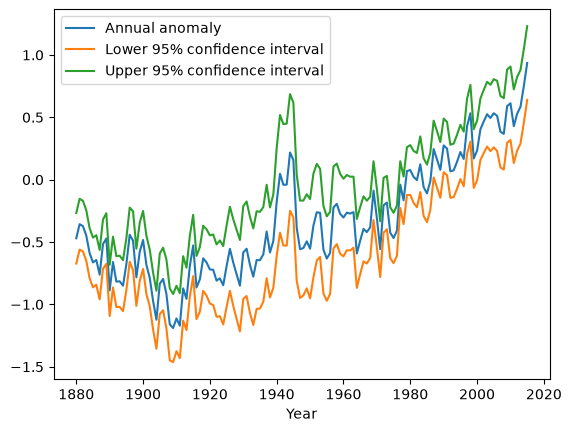

In [27]:
sst.plot()

I'm going to reset my universal plotting specs (I usually do this at the top with my import statements) to make the plot nice

In [28]:
#Set plotting formats
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = [13.0, 6.0]
mpl.rcParams['font.size'] = 16
mpl.rcParams['legend.fontsize'] = 'medium'
mpl.rcParams['figure.titlesize'] = 'medium'
mpl.rcParams['lines.linewidth'] = 2.0

<Axes: xlabel='Year'>

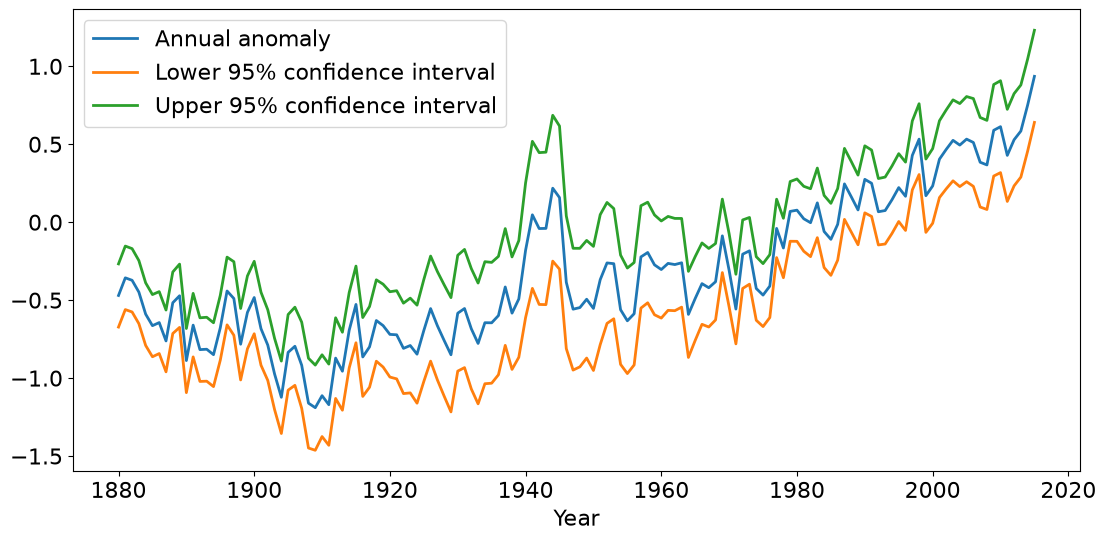

In [29]:
sst.plot()

1850 is usually considered the beginning of the industrial revolution, so before human affected climate by burning fossil fuels (but we did major land use changes and had impacts on many species' extinctions)

There is a definate trend in the data, with a big excursion in the 1940s

Let's ask some research questions. We will start these in lecture and you will finish them in lab:
- What is the trend in this data, that is how fast is SST increasing with time? 
- If we choose a different window for the trend analysis, how does this affect the answer?
- What causes all the interannual variablilty? If we detrend the data how does it look? Can we compare this with climate variabiltiy indices?
- What happened in the 1940s?

see: https://www.newscientist.com/article/dn11639-climate-myths-the-cooling-after-1940-shows-co2-does-not-cause-warming/

I am much more comfortable doing data analysis in xarray so I'm converting the pandas dataframe to an xarray dataset

In [30]:
import xarray as xr

In [31]:
sst_ds = sst.to_xarray()

In [32]:
sst_ds

<xarray.Dataset> Size: 4kB
Dimensions:                        (Year: 136)
Coordinates:
  * Year                           (Year) int64 1kB 1880 1881 1882 ... 2014 2015
Data variables:
    Annual anomaly                 (Year) float64 1kB -0.47 -0.3569 ... 0.9356
    Lower 95% confidence interval  (Year) float64 1kB -0.6726 -0.5606 ... 0.6401
    Upper 95% confidence interval  (Year) float64 1kB -0.2674 -0.1532 ... 1.231

If we want, we can add a pandas date range to this timeseries and use this for plotting. Not super needed here because it's annual, but would be useful if it was monthly or daily.

In [33]:
ssha_dates = pd.date_range(start = '1880', end = '2015', freq='YE')

In [34]:
ssha_dates

DatetimeIndex(['1880-12-31', '1881-12-31', '1882-12-31', '1883-12-31',
               '1884-12-31', '1885-12-31', '1886-12-31', '1887-12-31',
               '1888-12-31', '1889-12-31',
               ...
               '2005-12-31', '2006-12-31', '2007-12-31', '2008-12-31',
               '2009-12-31', '2010-12-31', '2011-12-31', '2012-12-31',
               '2013-12-31', '2014-12-31'],
              dtype='datetime64[us]', length=135, freq='YE-DEC')

In [35]:
# let's just work with the annual anomaly

sst_ds["Annual anomaly"] # note a lot of the syntax in xarray is similar to pandas

<xarray.DataArray 'Annual anomaly' (Year: 136)> Size: 1kB
array([-0.4700088, -0.3568788, -0.3726612, -0.448443 , -0.5897538,
       -0.6636546, -0.6439392, -0.7616232, -0.5166342, -0.4717926,
       -0.8875836, -0.6603264, -0.8173098, -0.8148276, -0.84978  ,
       -0.6772536, -0.4412844, -0.4894326, -0.78255  , -0.578736 ,
       -0.4833054, -0.6831072, -0.7883226, -0.9732618, -1.123038 ,
       -0.8347986, -0.795843 , -0.917685 , -1.160703 , -1.189773 ,
       -1.112769 , -1.1706066, -0.8718498, -0.9557658, -0.6931926,
       -0.5274864, -0.8644752, -0.7996338, -0.6306858, -0.6633414,
       -0.7196544, -0.7222464, -0.8093034, -0.7910208, -0.8465382,
       -0.6946722, -0.554238 , -0.6640884, -0.7589772, -0.8502282,
       -0.5835816, -0.5537106, -0.683568 , -0.7777674, -0.6447312,
       -0.6452784, -0.5988258, -0.4155462, -0.5834772, -0.4924098,
       -0.1797678,  0.0471582, -0.0406296, -0.039807 ,  0.2180826,
        0.157752 , -0.3853548, -0.5579568, -0.5477346, -0.4941792,
       -0.5531796, -0.368496 , -0.2612952, -0.2661372, -0.5613282,
       -0.632412 , -0.5871312, -0.2226618, -0.1943208, -0.2735424,
       -0.3035772, -0.2642508, -0.2717028, -0.260397 , -0.5913306,
       -0.489249 , -0.39411  , -0.4203576, -0.38187  , -0.0876366,
       -0.3086334, -0.5571756, -0.2051676, -0.1836738, -0.4251924,
       -0.4675428, -0.4096278, -0.0397692, -0.165393 ,  0.0692586,
        0.0771966,  0.0219924, -0.0032202,  0.1239354, -0.0596304,
       -0.109917 , -0.0137916,  0.2456388,  0.1634436,  0.0785898,
        0.274842 ,  0.2497932,  0.0669942,  0.0748224,  0.1436454,
        0.2219328,  0.1661922,  0.428193 ,  0.5327244,  0.1698606,
        0.2325024,  0.4042188,  0.4671414,  0.5250798,  0.4946364,
        0.5327874,  0.5114556,  0.3846042,  0.3673116,  0.5894424,
        0.6127182,  0.4286736,  0.528696 ,  0.5846742,  0.7512552,
        0.935577 ])
Coordinates:
  * Year     (Year) int64 1kB 1880 1881 1882 1883 1884 ... 2012 2013 2014 2015

#### Let's do a linear fit of the whole timeseries

Linear regression is simply fitting a line to some data, assuming that the data is on a straight line with the equation y=**m**x+**b**, where x and y are the independent and dependent data, **m** is the slope, and **b** is the intercept. Linear regression finds m and b by minimizing the distance of all the data points to a line, getting the best fit, using calculus. See:

https://plainenglish.io/blog/linear-regression-for-dummies

https://en.wikipedia.org/wiki/Linear_regression


In [36]:
from scipy import stats

In [37]:
stats.linregress?

Signature:
stats.linregress(
    x,
    y,
    alternative='two-sided',
    *,
    axis=0,
    nan_policy='propagate',
    keepdims=False,
)
Docstring:
Calculate a linear least-squares regression for two sets of measurements.

Parameters
----------
x, y : array_like
    Two sets of measurements.  Both arrays should have the same length N.
alternative : {'two-sided', 'less', 'greater'}, optional
    Defines the alternative hypothesis. Default is 'two-sided'.
    The following options are available:
    
    * 'two-sided': the slope of the regression line is nonzero
    * 'less': the slope of the regression line is less than zero
    * 'greater':  the slope of the regression line is greater than zero
    
    .. versionadded:: 1.7.0
axis : int or None, default: 0
    If an int, the axis of the input along which to compute the statistic.
    The statistic of each axis-slice (e.g. row) of the input will appear in a
    corresponding element of the output.
    If ``None``, the input will be

In [38]:
# the syntax for this function is x,y, so time, ssta
ssta_trend_entire = stats.linregress(sst_ds.Year, sst_ds["Annual anomaly"])

In [39]:
ssta_trend_entire

LinregressResult(slope=np.float64(0.010013503267496778), intercept=np.float64(-19.822035179626447), rvalue=np.float64(0.836269454413966), pvalue=np.float64(8.796275453012706e-37), stderr=np.float64(0.0005671794277975707), intercept_stderr=np.float64(1.1048063455210597))

In [40]:
ssta_trend_entire.slope

np.float64(0.010013503267496778)

The value I am interested in is the slope, what is this? What are the units?
- Rate that temperature is increasing (degrees F/Year)

Let's plot the line to see the fit. The equation is y = mx + b, where m is the slope and b is the intercept, what are x and y in this case?
- x is time
- y is temprature

In [41]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'SSTA ($\\degree$F)')

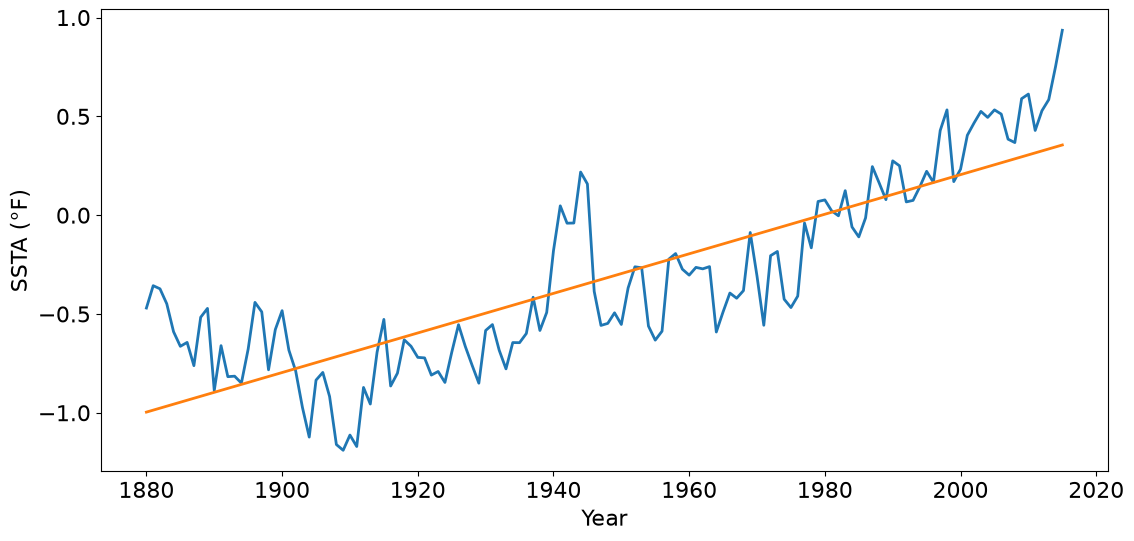

In [42]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])

# plot the line
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)

plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

How good of a fit is this for the last few decades?
It's not so good, the trend is bigger, steeper

#### Let's do a linear fit for the last few decades and see what we get.

How do we access the later data?

In [43]:
sst_ds.Year[100:]

<xarray.DataArray 'Year' (Year: 36)> Size: 288B
[36 values with dtype=int64]
Coordinates:
  * Year     (Year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015

In [44]:
sst_ds["Annual anomaly"][100:]

<xarray.DataArray 'Annual anomaly' (Year: 36)> Size: 288B
array([ 0.0771966,  0.0219924, -0.0032202,  0.1239354, -0.0596304,
       -0.109917 , -0.0137916,  0.2456388,  0.1634436,  0.0785898,
        0.274842 ,  0.2497932,  0.0669942,  0.0748224,  0.1436454,
        0.2219328,  0.1661922,  0.428193 ,  0.5327244,  0.1698606,
        0.2325024,  0.4042188,  0.4671414,  0.5250798,  0.4946364,
        0.5327874,  0.5114556,  0.3846042,  0.3673116,  0.5894424,
        0.6127182,  0.4286736,  0.528696 ,  0.5846742,  0.7512552,
        0.935577 ])
Coordinates:
  * Year     (Year) int64 288B 1980 1981 1982 1983 1984 ... 2012 2013 2014 2015

In [45]:
# the syntax for this function is x,y, so time, ssta
ssta_trend_1980_on = stats.linregress(sst_ds.Year[100:], sst_ds["Annual anomaly"][100:])

In [46]:
ssta_trend_1980_on

LinregressResult(slope=np.float64(0.020711260308880312), intercept=np.float64(-41.05951991698843), rvalue=np.float64(0.8829830021529422), pvalue=np.float64(1.0383113887943913e-12), stderr=np.float64(0.0018882626420977902), intercept_stderr=np.float64(3.7718556347573653))

In [47]:
ssta_trend_1980_on.slope # 0.02 F/ year. 0.2 F /10 years

np.float64(0.020711260308880312)

Text(0, 0.5, 'SSTA ($\\degree$F)')

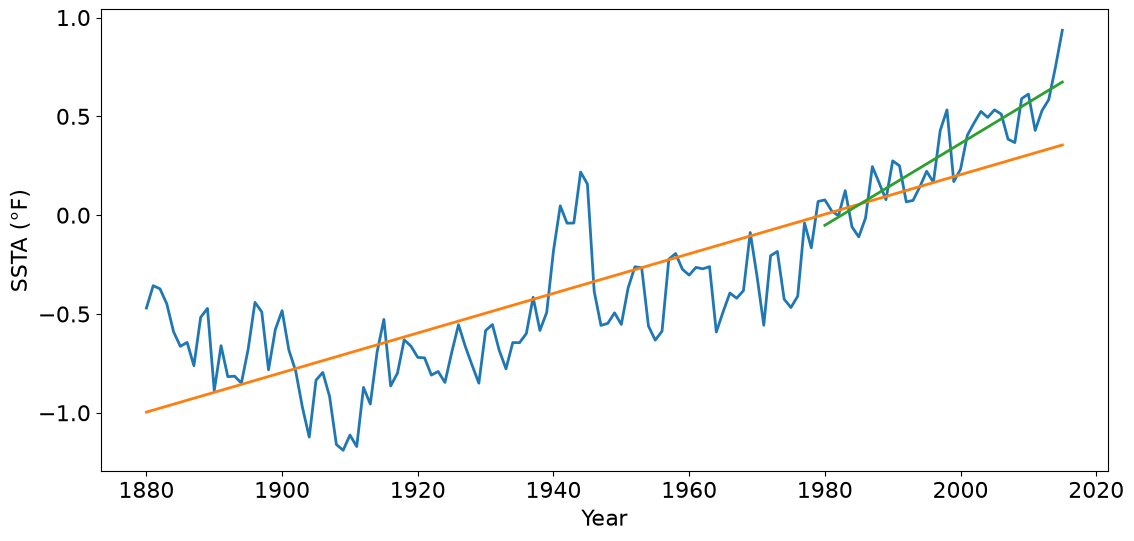

In [48]:
plt.plot(sst_ds.Year, sst_ds["Annual anomaly"])
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept)
plt.plot(sst_ds.Year[100:], ssta_trend_1980_on.slope*sst_ds.Year[100:] + ssta_trend_1980_on.intercept)
plt.xlabel('Year')
plt.ylabel('SSTA ($\degree$F)')

#### Detrending the data
Let's say we were interested in the variability outside of the trend. How do we detrend the data?

In [49]:
# First I am going to make the line, as I plotted before
trend_entire = ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept


In [50]:
trend_entire


<xarray.DataArray 'Year' (Year: 136)> Size: 1kB
array([-0.99664904, -0.98663553, -0.97662203, -0.96660853, -0.95659502,
       -0.94658152, -0.93656802, -0.92655451, -0.91654101, -0.90652751,
       -0.896514  , -0.8865005 , -0.876487  , -0.86647349, -0.85645999,
       -0.84644649, -0.83643298, -0.82641948, -0.81640598, -0.80639247,
       -0.79637897, -0.78636547, -0.77635196, -0.76633846, -0.75632496,
       -0.74631146, -0.73629795, -0.72628445, -0.71627095, -0.70625744,
       -0.69624394, -0.68623044, -0.67621693, -0.66620343, -0.65618993,
       -0.64617642, -0.63616292, -0.62614942, -0.61613591, -0.60612241,
       -0.59610891, -0.5860954 , -0.5760819 , -0.5660684 , -0.55605489,
       -0.54604139, -0.53602789, -0.52601438, -0.51600088, -0.50598738,
       -0.49597387, -0.48596037, -0.47594687, -0.46593336, -0.45591986,
       -0.44590636, -0.43589285, -0.42587935, -0.41586585, -0.40585234,
       -0.39583884, -0.38582534, -0.37581183, -0.36579833, -0.35578483,
       -0.34577132, -0.33575782, -0.32574432, -0.31573081, -0.30571731,
       -0.29570381, -0.2856903 , -0.2756768 , -0.2656633 , -0.25564979,
       -0.24563629, -0.23562279, -0.22560929, -0.21559578, -0.20558228,
       -0.19556878, -0.18555527, -0.17554177, -0.16552827, -0.15551476,
       -0.14550126, -0.13548776, -0.12547425, -0.11546075, -0.10544725,
       -0.09543374, -0.08542024, -0.07540674, -0.06539323, -0.05537973,
       -0.04536623, -0.03535272, -0.02533922, -0.01532572, -0.00531221,
        0.00470129,  0.01471479,  0.0247283 ,  0.0347418 ,  0.0447553 ,
        0.05476881,  0.06478231,  0.07479581,  0.08480932,  0.09482282,
        0.10483632,  0.11484983,  0.12486333,  0.13487683,  0.14489034,
        0.15490384,  0.16491734,  0.17493085,  0.18494435,  0.19495785,
        0.20497136,  0.21498486,  0.22499836,  0.23501187,  0.24502537,
        0.25503887,  0.26505237,  0.27506588,  0.28507938,  0.29509288,
        0.30510639,  0.31511989,  0.32513339,  0.3351469 ,  0.3451604 ,
        0.3551739 ])
Coordinates:
  * Year     (Year) int64 1kB 1880 1881 1882 1883 1884 ... 2012 2013 2014 2015

In [51]:
# Then I will subtract the trend, the line
sst_detrended = sst_ds["Annual anomaly"] - trend_entire

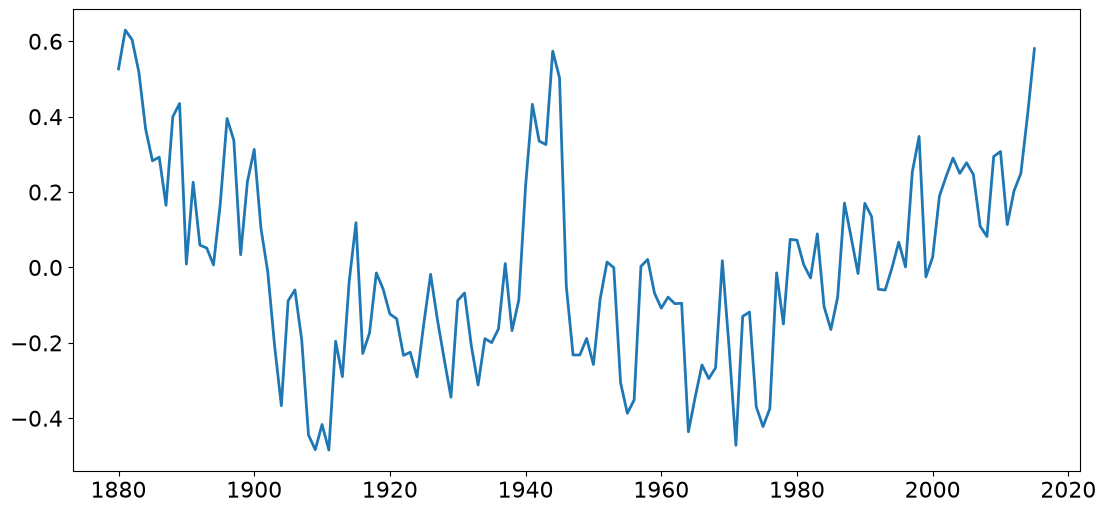

In [52]:
plt.plot(sst_ds.Year, sst_detrended)

#### Creating a moving average, i.e. filtering or smoothing.
Let's say we wanted to smooth the data to remove some of the variability, how would we do this?

I want to do a three year running mean, so for each datapoint, average the year before, the current year and the year after and save that to the current year as the new data.

if i is my current year index

(data[j+1] + data [j] + data [j-1])/3 to average the three years of data

Going to have to start at the second year, since I don't have a previous year


pseudo code:

create an array to save the new data in

Loop through all the years
 take a mean of the current, previous and next years, save to some new arrray


In [53]:
import numpy as np

In [54]:
sst_ds["Annual anomaly"].shape

(136,)

In [55]:
# initialize my array
ssta_filtered = np.zeros(136)

In [56]:
for i in range(134): # loop through all the years, skip the last index
    #print(i+1) #skip the first index
    ssta_filtered[i+1] = (sst_ds["Annual anomaly"][i] + sst_ds["Annual anomaly"][i+1] + sst_ds["Annual anomaly"][i+2])/3


In [57]:
ssta_filtered

array([ 0.       , -0.3998496, -0.392661 , -0.470286 , -0.5672838,
       -0.6324492, -0.689739 , -0.6407322, -0.58335  , -0.6253368,
       -0.6732342, -0.7884066, -0.7641546, -0.8273058, -0.7806204,
       -0.656106 , -0.5359902, -0.571089 , -0.6169062, -0.6148638,
       -0.5817162, -0.6515784, -0.8148972, -0.9615408, -0.9770328,
       -0.9178932, -0.8494422, -0.958077 , -1.089387 , -1.154415 ,
       -1.1577162, -1.0517418, -0.9994074, -0.8402694, -0.7254816,
       -0.6950514, -0.7305318, -0.7649316, -0.697887 , -0.6712272,
       -0.7017474, -0.7504014, -0.7741902, -0.8156208, -0.7774104,
       -0.6984828, -0.6376662, -0.6591012, -0.7577646, -0.730929 ,
       -0.6625068, -0.6069534, -0.671682 , -0.7020222, -0.689259 ,
       -0.6296118, -0.5532168, -0.5326164, -0.4971444, -0.4185516,
       -0.2083398, -0.0577464, -0.0110928,  0.045882 ,  0.1120092,
       -0.0031734, -0.2618532, -0.4970154, -0.5332902, -0.5316978,
       -0.4719516, -0.3943236, -0.2986428, -0.3629202, -0.4866

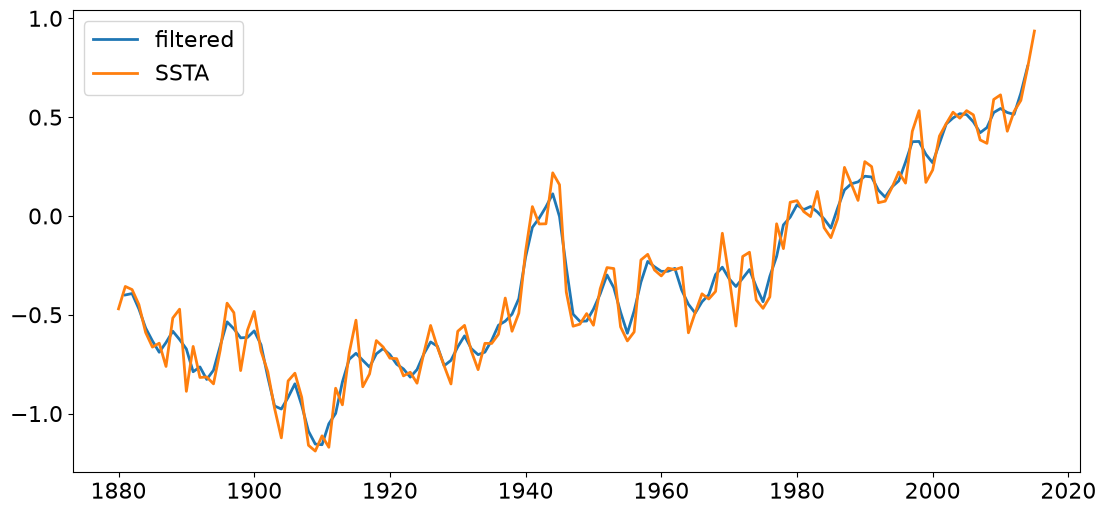

In [58]:
plt.plot(sst_ds.Year[1:-1],ssta_filtered[1:-1], label = "filtered")
plt.plot(sst_ds.Year,sst_ds["Annual anomaly"], label = 'SSTA')
plt.legend()

# Lab 12.1

**E.1** Define a datetime object that is your birthday. Increment this date using timedelta by a) ten weeks, b) five minutes, c) two years (tricky!) Hint: see help(timedelta)

In [59]:
birthday = datetime(1999, 2, 7)  
# 10 weeks later
print(birthday + timedelta(weeks=10))
# five minutes later
print(birthday + timedelta(minutes=5))

# two years later
# timedelta has no years, so I change the year directly here

print(birthday.replace(year=birthday.year + 2))

1999-04-18 00:00:00
1999-02-07 00:05:00
2001-02-07 00:00:00


**E.2** Define a daterange for your birthday every year of your life

In [60]:
birthdays = pd.date_range(start=birthday, end=datetime.today(), freq=pd.DateOffset(years=1))
birthdays

DatetimeIndex(['1999-02-07', '2000-02-07', '2001-02-07', '2002-02-07',
               '2003-02-07', '2004-02-07', '2005-02-07', '2006-02-07',
               '2007-02-07', '2008-02-07', '2009-02-07', '2010-02-07',
               '2011-02-07', '2012-02-07', '2013-02-07', '2014-02-07',
               '2015-02-07', '2016-02-07', '2017-02-07', '2018-02-07',
               '2019-02-07', '2020-02-07', '2021-02-07', '2022-02-07',
               '2023-02-07', '2024-02-07', '2025-02-07', '2026-02-07'],
              dtype='datetime64[us]', freq='<DateOffset: years=1>')

**E.3** Print all your birthdays out as month, day, year (no minutes, etc)

In [61]:
for b in birthdays:
    print(b.strftime("%m/%d/%Y")) # strftime actually turns the date into a text

02/07/1999
02/07/2000
02/07/2001
02/07/2002
02/07/2003
02/07/2004
02/07/2005
02/07/2006
02/07/2007
02/07/2008
02/07/2009
02/07/2010
02/07/2011
02/07/2012
02/07/2013
02/07/2014
02/07/2015
02/07/2016
02/07/2017
02/07/2018
02/07/2019
02/07/2020
02/07/2021
02/07/2022
02/07/2023
02/07/2024
02/07/2025
02/07/2026


**E.4** Do a linear fit of the SSTA data from 1940 to 1970. What trend do you get? How confident are you in this result? How does it compare to the trends we did in lecture (use quantitative data to explain).

In [62]:
# now, selecting only the years that are from 1940 to 1970

sst_4070 = sst_ds.sel(Year=slice(1940, 1970))

ssta_trend_4070 = stats.linregress(sst_4070.Year, sst_4070["Annual anomaly"])
ssta_trend_4070

LinregressResult(slope=np.float64(-0.008184913548387096), intercept=np.float64(15.69453642580645), rvalue=np.float64(-0.336258115900317), pvalue=np.float64(0.0643797087189174), stderr=np.float64(0.004256837897140221), intercept_stderr=np.float64(8.32220518488094))

In [63]:
#  now, I am putting the confidence interval

n = len(sst_4070.Year)                     # number of years (31)
t_crit = stats.t.ppf(0.975, n - 2)         # t-value for 95% with n-2 degrees of freedom
low = ssta_trend_4070.slope - t_crit * ssta_trend_4070.stderr
high = ssta_trend_4070.slope + t_crit * ssta_trend_4070.stderr

print("slope:", ssta_trend_4070.slope, "°F/year")
print("95% CI:", low, "to", high)
print("p-value:", ssta_trend_4070.pvalue)
print("R squared:", ssta_trend_4070.rvalue**2)

slope: -0.008184913548387096 °F/year
95% CI: -0.016891124597372124 to 0.0005212975005979299
p-value: 0.0643797087189174
R squared: 0.11306952050883103


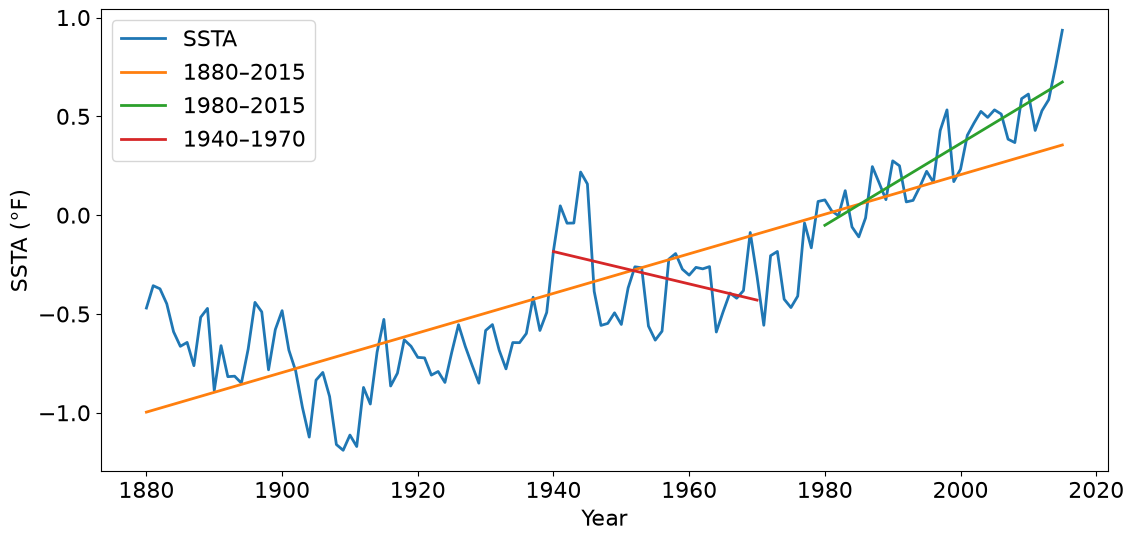

In [64]:
# now plotting all the data and also adding the trend line over here

# something that is super relevant to the following code is this that sst_ds.sel picks the row by the year value, this means
# that I do not have to count the indexes. This is because both 1940 and 1970 are included
# slope is exactly how the fast SST is changing in F per year
# stderr is just the uncertainty of the slope
# R^2 explains how much the up and down the line explains (0 means nothing and 1 means everything)

plt.plot(sst_ds.Year, sst_ds["Annual anomaly"], label="SSTA")
plt.plot(sst_ds.Year, ssta_trend_entire.slope*sst_ds.Year + ssta_trend_entire.intercept, label="1880–2015")
plt.plot(sst_ds.Year[100:], ssta_trend_1980_on.slope*sst_ds.Year[100:] + ssta_trend_1980_on.intercept, label="1980–2015")
plt.plot(sst_4070.Year, ssta_trend_4070.slope*sst_4070.Year + ssta_trend_4070.intercept, label="1940–1970")
plt.xlabel("Year")
plt.ylabel("SSTA ($\\degree$F)")
plt.legend()

**E.5** According to the internet, what might have caused this decline in SST during this perioud? Write a few sentances explaining this and cite your sources here.

Sources:

New Scientist, “Climate myths: The cooling after 1940 shows CO2 does not cause warming”: https://www.newscientist.com/article/dn11639-climate-myths-the-cooling-after-1940-shows-co2-does-not-cause-warming/

Thompson, D. W. J., Kennedy, J. J., Wallace, J. M., & Jones, P. D. (2008). A large discontinuity in the mid-twentieth century in observed global-mean surface temperature. Nature, 453, 646–649.

**E.6** Detrend from 1970 on and plot your result. Compare this to an ENSO (El Nino) index and speculate on what may have caused this interannual variability. How does ENSO affect SST and why?

In [65]:
sst_70 = sst_ds.sel(Year=slice(1970, None))
ssta_trend_70 = stats.linregress(sst_70.Year, sst_70["Annual anomaly"])
trend_70 = ssta_trend_70.slope*sst_70.Year + ssta_trend_70.intercept
sst_70_detrended = sst_70["Annual anomaly"] - trend_70

# now comparing it with ENSO
# Positive = El Nino
# negative = La Nina

oni = pd.read_csv("https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt", sep=r"\s+") # oni defines how warmer or colder the tropical pacific is when compared to the normal. 
oni_annual = oni.groupby("YR")["ANOM"].mean()  # groupby here would group the 12 files that have the overlapping 3-month seasons per year.Also, it averages them per year as well. This results in one value per year
oni_annual = oni_annual.loc[1970:2015]              

Text(0.5, 1.0, 'Detrended global SST vs ENSO, 1970–2015')

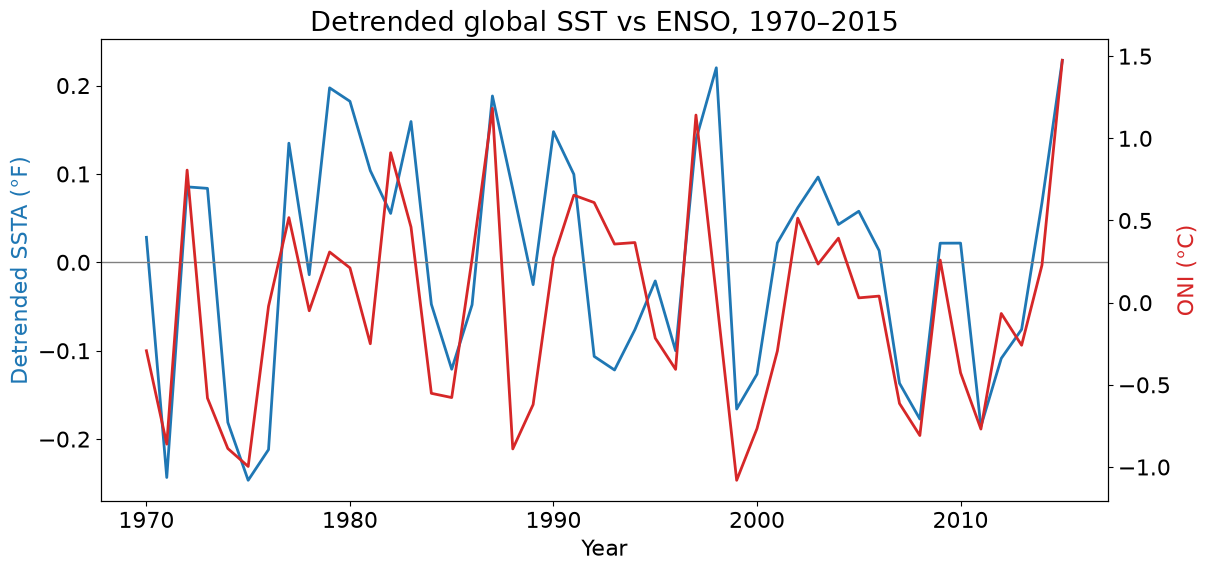

In [66]:
fig, ax1 = plt.subplots()
ax1.plot(sst_70_detrended.Year, sst_70_detrended, color="tab:blue", label="Detrended SSTA")
ax1.set_xlabel("Year")
ax1.set_ylabel("Detrended SSTA ($\\degree$F)", color="tab:blue")
ax1.axhline(0, color="gray", lw=1)

ax2 = ax1.twinx() # twinx() here is actually the second y-axis. 
ax2.plot(oni_annual.index, oni_annual.values, color="tab:red", label="ONI (ENSO)")
ax2.set_ylabel("ONI ($\\degree$C)", color="tab:red")
plt.title("Detrended global SST vs ENSO, 1970–2015")

In [67]:
# how similar (correlated) are they?

print(np.corrcoef(sst_70_detrended.values, oni_annual.values)[0, 1]) # np.corrcoef here defines the correlation from -1 to + 1.
# Here, positive means warm global SST years ago with El Nino years.

0.6591298324590729


**E.7** Perform a five year moving average of your detrended data from E.6. Explain your result in relation to the periodicity of ENSO.

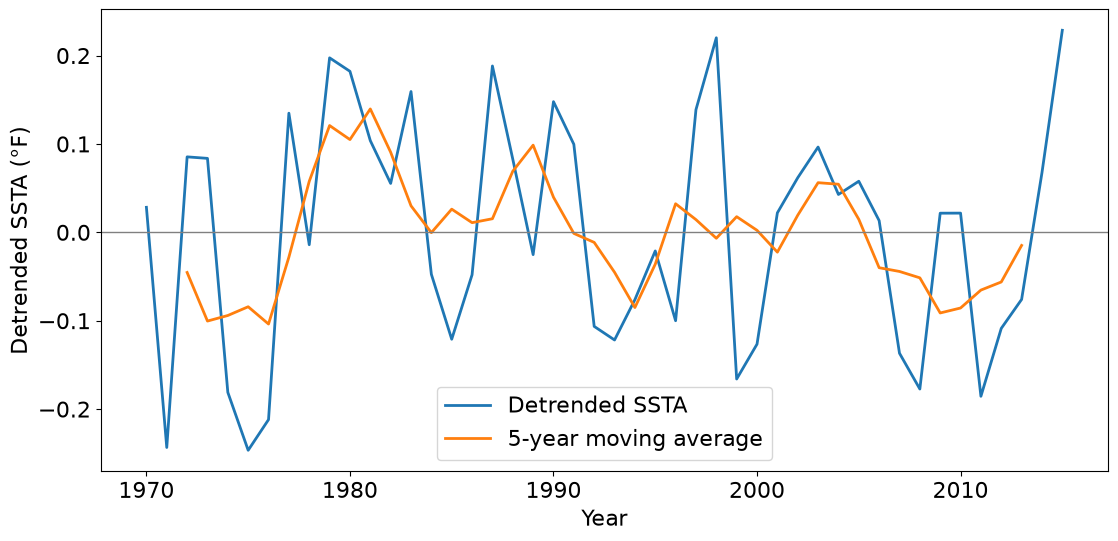

In [68]:
# now making the 5 year moving average
# centre = True would put each average in the middle year
sst_70_smooth = sst_70_detrended.rolling(Year=5, center=True).mean()

plt.plot(sst_70_detrended.Year, sst_70_detrended, label="Detrended SSTA")
plt.plot(sst_70_smooth.Year, sst_70_smooth, label="5-year moving average")
plt.axhline(0, color="gray", lw=1)
plt.xlabel("Year")
plt.ylabel("Detrended SSTA ($\\degree$F)")
plt.legend()

ENSO actually repeats roughly every 2 -7 years. In fact, with a 5-year average, El Nino and La Nina years mix together. Hence, most of 
the ENSO ups and downs get smoothed out. What remains after that is slower but longer changes. 

**Notes** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.